# XGBoost model training and 2026 evaluation

## Academic objective

Gradient-boosted trees build an additive predictor by repeatedly fitting a tree to reduce a regularized loss. At boosting step *m*, the new tree approximates the negative gradient of the loss with respect to the current predictions. XGBoost adds shrinkage, row subsampling, column subsampling, and tree-complexity penalties to control overfitting.

For regression, the objective is commonly written as

    Obj = Σᵢ l(yᵢ, ŷᵢ) + Σₘ Ω(fₘ),    Ω(f) = γT + ½λΣⱼwⱼ²

where *l* is squared error, *T* is the number of leaves, *wⱼ* are leaf scores, and γ and λ penalize complexity. Tabular technical indicators and lagged prices suit trees because interactions and nonlinear thresholds can be learned without feature scaling. Limits include regime shift, extrapolation difficulty, sensitivity to feature design, and no native understanding of sequence order.

**Information boundary:** fit candidates on 2018–2023, choose estimator count using 2024, refit through 2025, then evaluate on available 2026 targets. The 2026 rows do not enter fitting or selection. No external checkpoint or pretrained tree is used.

## 1. Reproducible project setup

The notebook reuses the project's causal feature builder, `XGBoostForecaster`, target-leakage guard, and common metrics. It adds visual explanations of the fitted booster without replacing production model logic.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import sys
import uuid
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "btc_forecasting").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the BTC forecasting project.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from btc_forecasting.data import load_ohlcv_csv
from btc_forecasting.features import make_features
from btc_forecasting.metrics import evaluate_predictions

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

CONFIG_PATH = PROJECT_ROOT / "configs" / "default.yaml"
with CONFIG_PATH.open(encoding="utf-8") as stream:
    PROJECT_CONFIG = yaml.safe_load(stream)

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def package_version(name: str) -> str:
    try:
        return version(name)
    except PackageNotFoundError:
        return "not-installed"

def make_run_id(model_name: str) -> str:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    return f"{stamp}_notebook_{model_name}_{uuid.uuid4().hex[:8]}"

PLOT_OUTPUTS = {}
EXTRA_TABLES = {}

def capture_plot(name, figure):
    import io
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
    PLOT_OUTPUTS[name] = buffer.getvalue()

def save_run(model_name, run_id, predictions, metrics, validation_scores,
             configuration, model_metadata, save_model):
    """Create a new run directory and refuse every path collision."""
    run_dir = PROJECT_ROOT / "artifacts" / "runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    model_dir = run_dir / "models"
    model_dir.mkdir()
    model_relative_path = save_model(model_dir)
    for name, image_bytes in PLOT_OUTPUTS.items():
        (run_dir / name).write_bytes(image_bytes)
    for name, table in EXTRA_TABLES.items():
        table.to_csv(run_dir / name, index=True)
    predictions.to_csv(run_dir / "predictions.csv", index=False)
    metrics.to_csv(run_dir / "metrics.csv", index_label="model")
    validation_scores.to_csv(run_dir / "validation_scores.csv", index=False)
    (run_dir / "configuration.json").write_text(
        json.dumps(configuration, indent=2, sort_keys=True, default=str) + "\n",
        encoding="utf-8",
    )
    metadata = {
        "run_id": run_id,
        "notebook_experiment": True,
        "notebook_model": model_name,
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_sha256": RAW_SHA256,
        "raw_data_sha256": RAW_SHA256,
        "features_sha256": FEATURES_SHA256,
        "raw_data_file": str(RAW_PATH),
        "target_column": TARGET_COLUMN,
        "horizon_days": 1,
        "prediction_index": "decision date; target date is the following calendar date",
        "split_ranges_by_target_date": SPLIT_CONFIG,
        "rows": {"train": len(TRAIN), "validation": len(VALIDATION),
                 "final_fit": len(DEVELOPMENT), "final_evaluation": len(TEST)},
        "feature_columns": FEATURE_COLUMNS,
        "model": model_metadata,
        "model_artifacts": {model_name: model_relative_path},
        "software_versions": {
            "python": platform.python_version(),
            "numpy": package_version("numpy"),
            "pandas": package_version("pandas"),
            "statsmodels": package_version("statsmodels"),
            "pmdarima": package_version("pmdarima"),
            "scikit-learn": package_version("scikit-learn"),
            "xgboost": package_version("xgboost"),
            "torch": package_version("torch"),
            "matplotlib": package_version("matplotlib"),
        },
    }
    (run_dir / "metadata.json").write_text(
        json.dumps(metadata, indent=2, sort_keys=True, default=str) + "\n",
        encoding="utf-8",
    )
    return run_dir

## 2. Data provenance and temporal partitions

The notebook uses the newest immutable OHLCV snapshot already present in `data/raw/`. It does not download or replace data. Features are rebuilt with the project's causal feature function; no feature row uses a later candle. The next-close target is kept separate from the model inputs.

Training and validation are assigned by **target date**. A row dated *t* uses information through the close on *t* and predicts *t+1*. Thus the train/validation boundary does not accidentally put a January 1 target into training merely because its decision row is dated December 31.

In [2]:
import hashlib
from btc_forecasting.features import TARGET_COLUMNS

RAW_DIRECTORY = PROJECT_ROOT / "data" / "raw"
raw_candidates = sorted(RAW_DIRECTORY.glob("*.csv"))
if not raw_candidates:
    raise FileNotFoundError("No raw OHLCV snapshots found under data/raw/.")
RAW_PATH = raw_candidates[-1]
raw = load_ohlcv_csv(RAW_PATH)
RAW_SHA256 = sha256_file(RAW_PATH)
TARGET_COLUMN = PROJECT_CONFIG["target"]["column"]
if TARGET_COLUMN != "Target_Next_Close":
    raise ValueError("These demonstrations require the project's one-day next-close target.")

frame = make_features(raw, drop_incomplete=False)
FEATURE_COLUMNS = [c for c in frame.columns if c not in TARGET_COLUMNS and not str(c).startswith("Target_")]
frame = frame.dropna(subset=FEATURE_COLUMNS).copy()
frame["Target_Date"] = frame.index + pd.Timedelta(days=1)
frame["Target_Next_Close"] = pd.to_numeric(frame["Target_Next_Close"], errors="coerce")
frame = frame.replace([np.inf, -np.inf], np.nan)
FEATURES_SHA256 = hashlib.sha256(
    frame.reset_index().to_csv(index=False, date_format="%Y-%m-%d").encode("utf-8")
).hexdigest()

SPLIT_CONFIG = {
    "training_target_dates": ["2018-01-01", "2023-12-31"],
    "validation_target_dates": ["2024-01-01", "2024-12-31"],
    "final_fit_target_dates": ["2018-01-01", "2025-12-31"],
    "final_evaluation_target_dates": ["2026-01-01", str(raw.index[-1].date())],
    "evaluation_strategy": "rolling one-day-ahead; weights and hyperparameters frozen throughout 2026",
}
target_dates = frame["Target_Date"]
has_target = frame[TARGET_COLUMN].notna()
TRAIN = frame.loc[has_target & (target_dates <= "2023-12-31")].copy()
VALIDATION = frame.loc[
    has_target & target_dates.between("2024-01-01", "2024-12-31", inclusive="both")
].copy()
DEVELOPMENT = frame.loc[has_target & (target_dates <= "2025-12-31")].copy()
TEST = frame.loc[has_target & (target_dates >= "2026-01-01")].copy()

assert not TRAIN.empty and not VALIDATION.empty and not DEVELOPMENT.empty and not TEST.empty
assert TRAIN["Target_Date"].max() <= pd.Timestamp("2023-12-31")
assert VALIDATION["Target_Date"].min() >= pd.Timestamp("2024-01-01")
assert VALIDATION["Target_Date"].max() <= pd.Timestamp("2024-12-31")
assert DEVELOPMENT["Target_Date"].max() <= pd.Timestamp("2025-12-31")
assert TEST["Target_Date"].min() >= pd.Timestamp("2026-01-01")
assert TEST["Target_Date"].max() <= raw.index[-1]

print(f"Raw source: {RAW_PATH}")
print(f"Raw SHA-256: {RAW_SHA256}")
print(f"Feature SHA-256: {FEATURES_SHA256}")
print(f"Latest observed BTC close date: {raw.index[-1].date()}")
print(f"Last target date with an actual next close: {TEST['Target_Date'].max().date()}")
display(pd.DataFrame([
    {"partition": "Train", "first_target_date": TRAIN.Target_Date.min().date(),
     "last_target_date": TRAIN.Target_Date.max().date(), "rows": len(TRAIN)},
    {"partition": "Validation", "first_target_date": VALIDATION.Target_Date.min().date(),
     "last_target_date": VALIDATION.Target_Date.max().date(), "rows": len(VALIDATION)},
    {"partition": "Final model fit", "first_target_date": DEVELOPMENT.Target_Date.min().date(),
     "last_target_date": DEVELOPMENT.Target_Date.max().date(), "rows": len(DEVELOPMENT)},
    {"partition": "Unseen 2026 evaluation", "first_target_date": TEST.Target_Date.min().date(),
     "last_target_date": TEST.Target_Date.max().date(), "rows": len(TEST)},
]))

feature_columns = FEATURE_COLUMNS
train = TRAIN
validation = VALIDATION
development = DEVELOPMENT
test = TEST

Raw source: C:\Users\Manya Chaubey\Downloads\Crypto\data\raw\BTC-USD_20180101_20261114_20261115T172122Z.csv
Raw SHA-256: deb1ce1e9955cfb8290783516159e9519c7337f3fb95e320401332d622a18e87
Feature SHA-256: 1210f3dd28aceb38e2d22859c4fd2fd7de19b7850f7c2bc4002f6b7a7d1f0533
Latest observed BTC close date: 2026-11-14
Last target date with an actual next close: 2026-11-14


,partition,first_target_date,last_target_date,rows
0,Train,2018-07-20,2023-12-31,1991
1,Validation,2024-01-01,2024-12-31,366
2,Final model fit,2018-07-20,2025-12-31,2722
3,Unseen 2026 evaluation,2026-01-01,2026-11-14,318


## 3. Validation-based estimator selection

Each candidate begins from a new booster initialized with the same fixed seed. Validation rows are scored only after fitting on the training partition. RMSE in USD is the selection criterion, matching the project configuration.

In [3]:
from btc_forecasting.models.xgboost_model import XGBoostForecaster

xgb_config = PROJECT_CONFIG["xgboost"]
common_parameters = {
    key: xgb_config[key]
    for key in ("max_depth", "learning_rate", "subsample", "colsample_bytree", "random_state")
}
candidate_estimators = list(xgb_config["n_estimators_candidates"])
validation_rows = []
for n_estimators in candidate_estimators:
    candidate = XGBoostForecaster(n_estimators=int(n_estimators), **common_parameters)
    candidate.fit(TRAIN[FEATURE_COLUMNS], TRAIN[TARGET_COLUMN])
    forecast = candidate.predict(VALIDATION[FEATURE_COLUMNS])
    scores = evaluate_predictions(VALIDATION[TARGET_COLUMN], forecast, VALIDATION["Close"])
    validation_rows.append({"n_estimators": int(n_estimators), **scores})
validation_scores = pd.DataFrame(validation_rows).sort_values("rmse").reset_index(drop=True)
best_estimators = int(validation_scores.loc[0, "n_estimators"])
display(validation_scores.round(4))
print(f"Selected tree count by 2024 validation RMSE: {best_estimators}")

,n_estimators,mae,rmse,directional_accuracy
0,300,7880.1979,13894.9116,0.4809
1,500,7935.8643,13945.1740,0.4863
2,800,7955.4489,13963.9796,0.4836


Selected tree count by 2024 validation RMSE: 300


## 4. Final fit through December 31, 2025

Refit the selected configuration from a fresh initialization using every labeled target through 2025-12-31. The 2026 forecast uses only each decision row's causal features. The fitted tree parameters remain fixed throughout the 2026 sequence.

2026 final evaluation, USD close-price errors:


,mae,rmse,directional_accuracy
XGBoost,1892.7047,2454.6569,0.4811


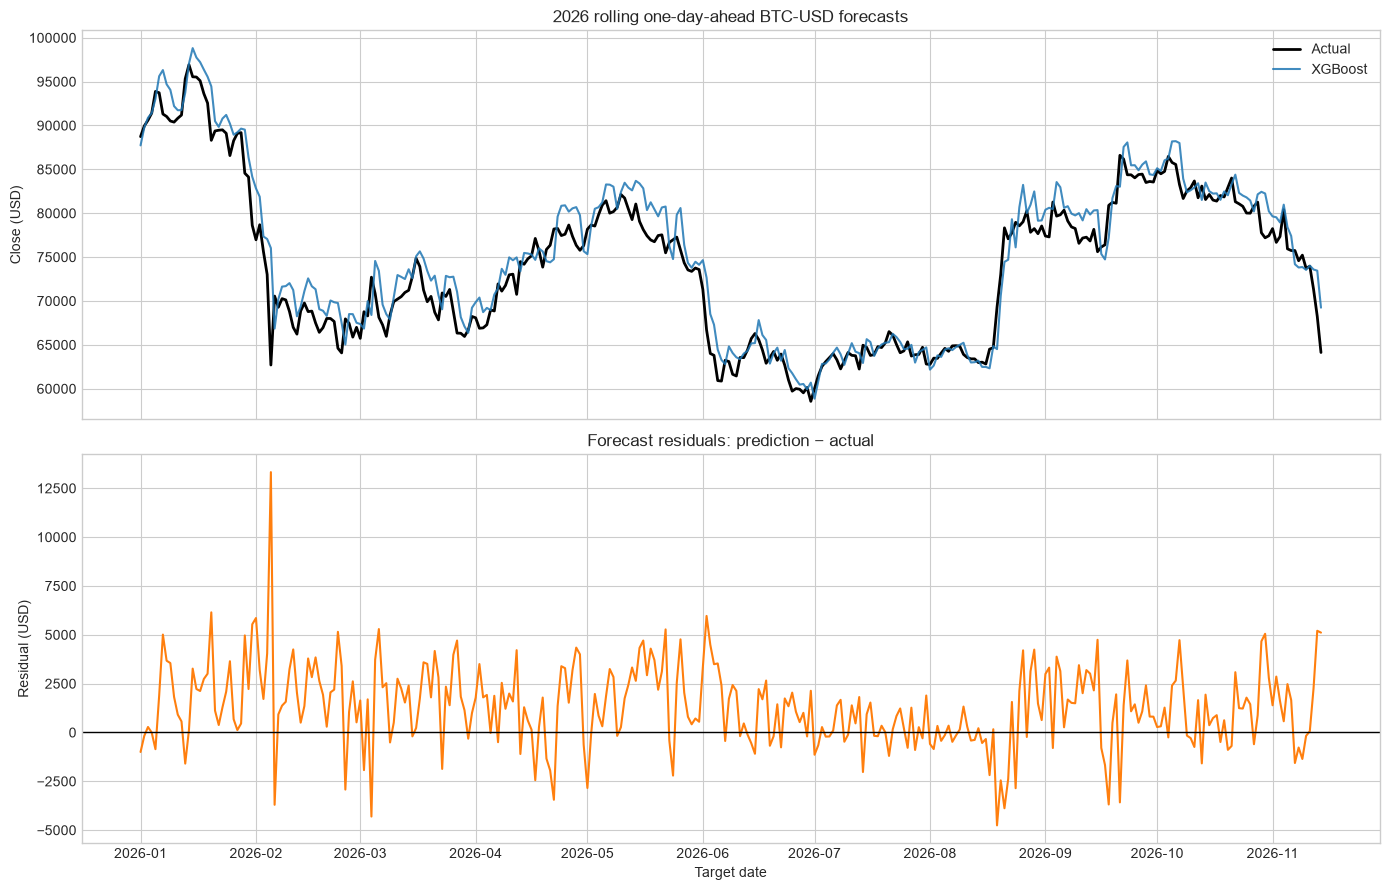

In [4]:
final_xgboost = XGBoostForecaster(
    n_estimators=best_estimators, **common_parameters
).fit(DEVELOPMENT[FEATURE_COLUMNS], DEVELOPMENT[TARGET_COLUMN])
xgb_prediction = final_xgboost.predict(TEST[FEATURE_COLUMNS])
xgb_metrics = evaluate_predictions(TEST[TARGET_COLUMN], xgb_prediction, TEST["Close"])
print("2026 final evaluation, USD close-price errors:")
display(pd.DataFrame([xgb_metrics], index=["XGBoost"]).round(4))

predictions = pd.DataFrame({
    "decision_date": TEST.index,
    "Target_Date": TEST["Target_Date"].to_numpy(),
    "previous_close_usd": TEST["Close"].to_numpy(),
    "actual_next_close_usd": TEST[TARGET_COLUMN].to_numpy(),
    "prediction_usd": xgb_prediction.to_numpy(),
})
residuals = predictions["prediction_usd"] - predictions["actual_next_close_usd"]
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(predictions["Target_Date"], predictions["actual_next_close_usd"],
             label="Actual", color="black", linewidth=2)
axes[0].plot(predictions["Target_Date"], predictions["prediction_usd"],
             label="XGBoost", alpha=0.85)
axes[0].set_title("2026 rolling one-day-ahead BTC-USD forecasts")
axes[0].set_ylabel("Close (USD)")
axes[0].legend()
axes[1].plot(predictions["Target_Date"], residuals, color="tab:orange")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Forecast residuals: prediction − actual")
axes[1].set_ylabel("Residual (USD)")
axes[1].set_xlabel("Target date")
fig.tight_layout()
capture_plot("2026_forecast_and_residuals.png", fig)
display(fig)
plt.close(fig)

## 5. Feature importance and a fitted decision tree

Gain importance measures the total improvement attributed to splits on a feature across the ensemble. It is descriptive, not causal, and correlated features can divide importance. The diagram below draws the actual first fitted tree by traversing its JSON dump; each internal node displays the split and each leaf its score.

,gain_importance
Close,2.913336e+10
Low,2.095971e+10
High,8.750718e+09
Close_Lag_1,6.720950e+09
Close_Lag_2,3.251627e+09
Open,2.297620e+09
EMA_14,1.480944e+09
Close_Lag_3,1.106838e+09
SMA_7,1.076668e+09
EMA_7,4.370490e+08


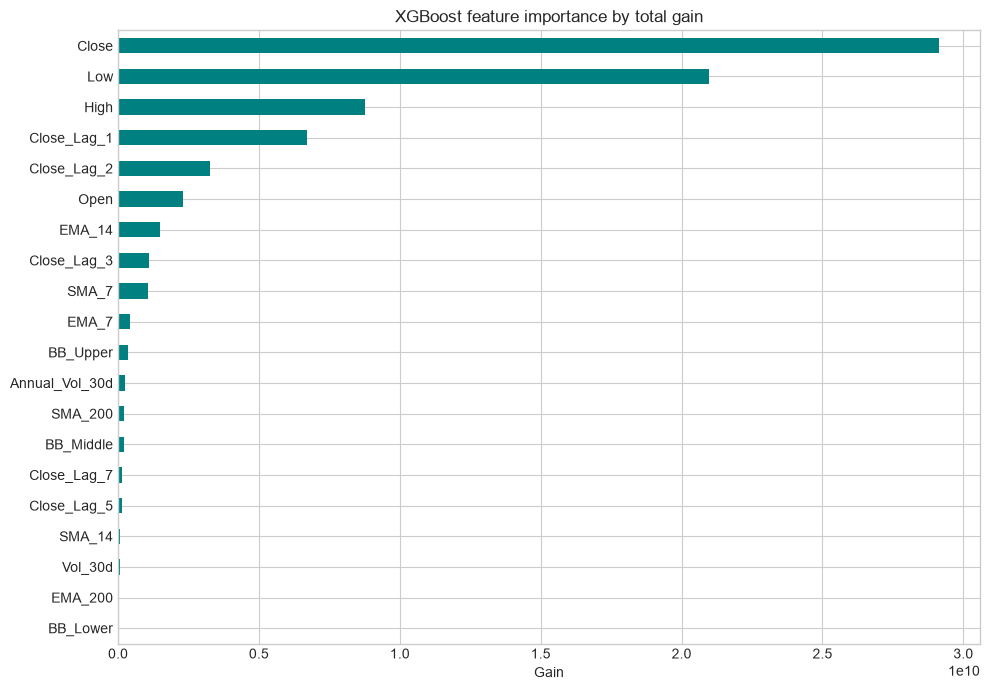

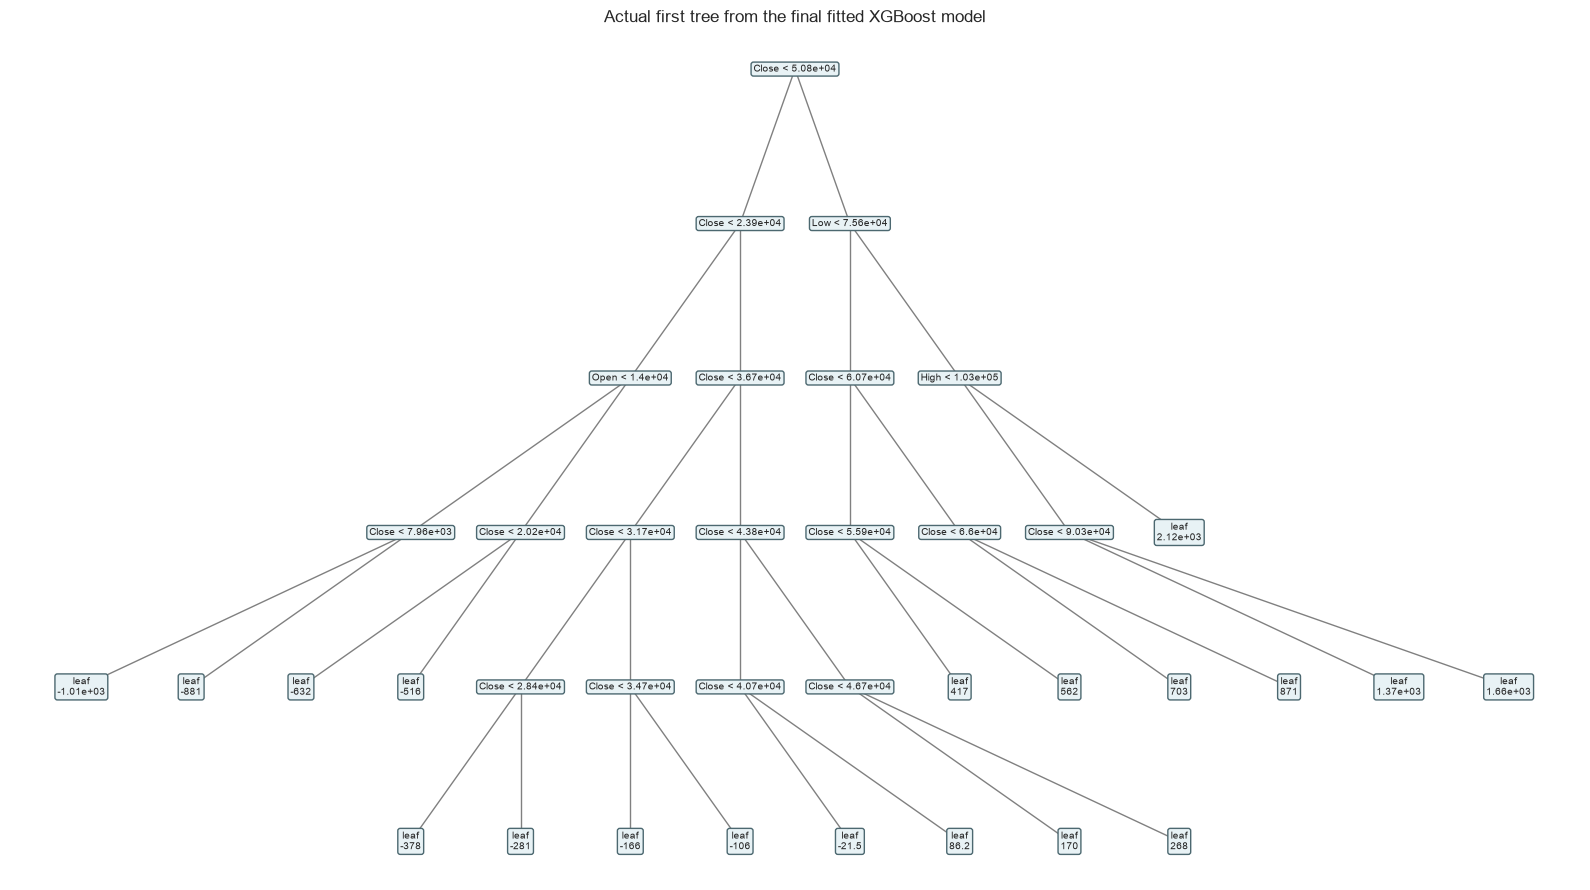

In [5]:
booster = final_xgboost._model.get_booster()
importance = pd.Series(booster.get_score(importance_type="gain"), dtype=float)
importance.index = [
    FEATURE_COLUMNS[int(name[1:])] if name.startswith("f") and name[1:].isdigit() else name
    for name in importance.index
]
importance = importance.sort_values(ascending=False)
display(importance.head(20).rename("gain_importance").to_frame())
fig, ax = plt.subplots(figsize=(10, 7))
importance.head(20).sort_values().plot.barh(ax=ax, color="teal")
ax.set_title("XGBoost feature importance by total gain")
ax.set_xlabel("Gain")
fig.tight_layout()
capture_plot("feature_importance.png", fig)
display(fig)
plt.close(fig)

import json as _json
first_tree = _json.loads(booster.get_dump(dump_format="json")[0])
tree_nodes = []
tree_edges = []
def collect_tree(node, depth=0):
    node_id = int(node["nodeid"])
    tree_nodes.append((node_id, depth, node))
    for child in node.get("children", []):
        tree_edges.append((node_id, int(child["nodeid"])))
        collect_tree(child, depth + 1)
collect_tree(first_tree)
levels = {}
for node_id, depth, node in tree_nodes:
    levels.setdefault(depth, []).append(node_id)
positions = {}
for depth, node_ids in levels.items():
    for i, node_id in enumerate(node_ids):
        positions[node_id] = (i - (len(node_ids) - 1) / 2, -depth)
fig, ax = plt.subplots(figsize=(16, 9))
for parent, child in tree_edges:
    x1, y1 = positions[parent]; x2, y2 = positions[child]
    ax.plot([x1, x2], [y1, y2], color="gray", linewidth=1)
for node_id, depth, node in tree_nodes:
    x, y = positions[node_id]
    if "leaf" in node:
        label = f"leaf\n{float(node['leaf']):.3g}"
    else:
        split = str(node["split"])
        if split.startswith("f") and split[1:].isdigit():
            split = FEATURE_COLUMNS[int(split[1:])]
        label = f"{split} < {float(node['split_condition']):.3g}"
    ax.text(x, y, label, ha="center", va="center", fontsize=7,
            bbox={"boxstyle": "round,pad=0.25", "facecolor": "#e8f2f5", "edgecolor": "#4c6870"})
ax.set_title("Actual first tree from the final fitted XGBoost model")
ax.axis("off")
fig.tight_layout()
capture_plot("first_fitted_tree.png", fig)
display(fig)
plt.close(fig)

## 6. Save and reload the trained booster

The native JSON booster plus metadata is saved into a new run directory. The verification below uses the same project adapter used by the API and confirms predictions survive save/load.

In [6]:
from btc_forecasting.models.xgboost_model import XGBoostForecaster

EXTRA_TABLES["feature_importance.csv"] = importance.rename("gain_importance").to_frame()
RUN_ID = make_run_id("xgboost")
XGB_CONFIG = {
    "candidate_n_estimators": candidate_estimators,
    "selected_n_estimators": best_estimators,
    "selection_metric": "2024 validation RMSE",
    "final_fit_target_end": "2025-12-31",
    "final_evaluation": "2026 rolling one-day-ahead; no refitting or tuning",
    "common_parameters": common_parameters,
}
xgb_metadata = {
    "xgboost": {
        "selected_n_estimators": best_estimators,
        "selection_metric": "2024 validation RMSE",
        "parameters": {**common_parameters, "n_estimators": best_estimators},
        "refit_during_2026": False,
    }
}
XGB_METRICS = pd.DataFrame([xgb_metrics], index=["xgboost"])

def save_xgboost_artifact(model_dir):
    final_xgboost.save(model_dir / "xgboost.json")
    return "models/xgboost.json"

RUN_DIR = save_run("xgboost", RUN_ID, predictions, XGB_METRICS,
                   validation_scores, XGB_CONFIG, xgb_metadata, save_xgboost_artifact)
loaded_xgboost = XGBoostForecaster.load(
    RUN_DIR / "models" / "xgboost.json",
    feature_columns=FEATURE_COLUMNS,
    parameters=xgb_metadata["xgboost"]["parameters"],
)
round_trip = loaded_xgboost.predict(TEST[FEATURE_COLUMNS].iloc[:10])
assert np.allclose(round_trip.to_numpy(), xgb_prediction.iloc[:10].to_numpy(), rtol=1e-6, atol=1e-6)
from btc_forecasting.api.service import _cached_model
production_xgboost = _cached_model("xgboost", RUN_DIR / "models" / "xgboost.json",
                                   json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8")))
assert np.allclose(production_xgboost.predict(TEST[FEATURE_COLUMNS].iloc[:10]).to_numpy(),
                   xgb_prediction.iloc[:10].to_numpy(), rtol=1e-6, atol=1e-6)
print(f"Saved native booster: {RUN_DIR / 'models' / 'xgboost.json'}")
print("Production API loader and XGBoost adapter reload checks: passed on 10 2026 examples.")

Saved native booster: C:\Users\Manya Chaubey\Downloads\Crypto\artifacts\runs\20261115T175648962901Z_notebook_xgboost_0c0c883d\models\xgboost.json
Production API loader and XGBoost adapter reload checks: passed on 10 2026 examples.


## Rolling one-day-ahead versus a fixed 365-day forecast

**Rolling one-day-ahead (used here):** at each decision date, predict only the next close using information then available. Once that date has passed and its close is observed, it may enter later causal features or update ARIMA's state. The learned XGBoost/LSTM parameters and selected hyperparameters remain fixed throughout 2026; ARIMA parameters remain fixed while its state receives already-observed closes. This estimates a repeated operational one-day forecast.

**Fixed-origin 365-day forecast:** at a single origin such as December 31, 2025, produce all forecasts through 2026 without observing any 2026 close between steps. This measures a long-horizon path and requires recursive features or a model that directly predicts all horizons. The existing XGBoost/LSTM one-step feature set cannot produce that path honestly because future OHLCV indicators are unknown. These notebooks therefore do not label rolling forecasts as a 365-day fixed-origin forecast.

The 2026 evaluation ends at the last date with an actual next close in the available raw dataset. Scores describe only that observed interval and should not be generalized to the full calendar year if later dates are unavailable.

## 8. Rolling evaluation and three-model comparison

The comparison cell below reads only completed notebook experiment folders with the same raw-data hash and the same target-date evaluation window. Run all three training notebooks first, then execute this cell in any notebook to refresh the shared comparison. It recomputes metrics from the saved per-date forecasts, verifies that actuals and target dates match, and saves a comparison table and plot in this notebook's unique experiment folder.

,mae,rmse,directional_accuracy
model,,,
arima,1181.2662,1728.3102,0.4874
xgboost,1892.7047,2454.6569,0.4811
lstm,1208.5267,1752.0206,0.4748


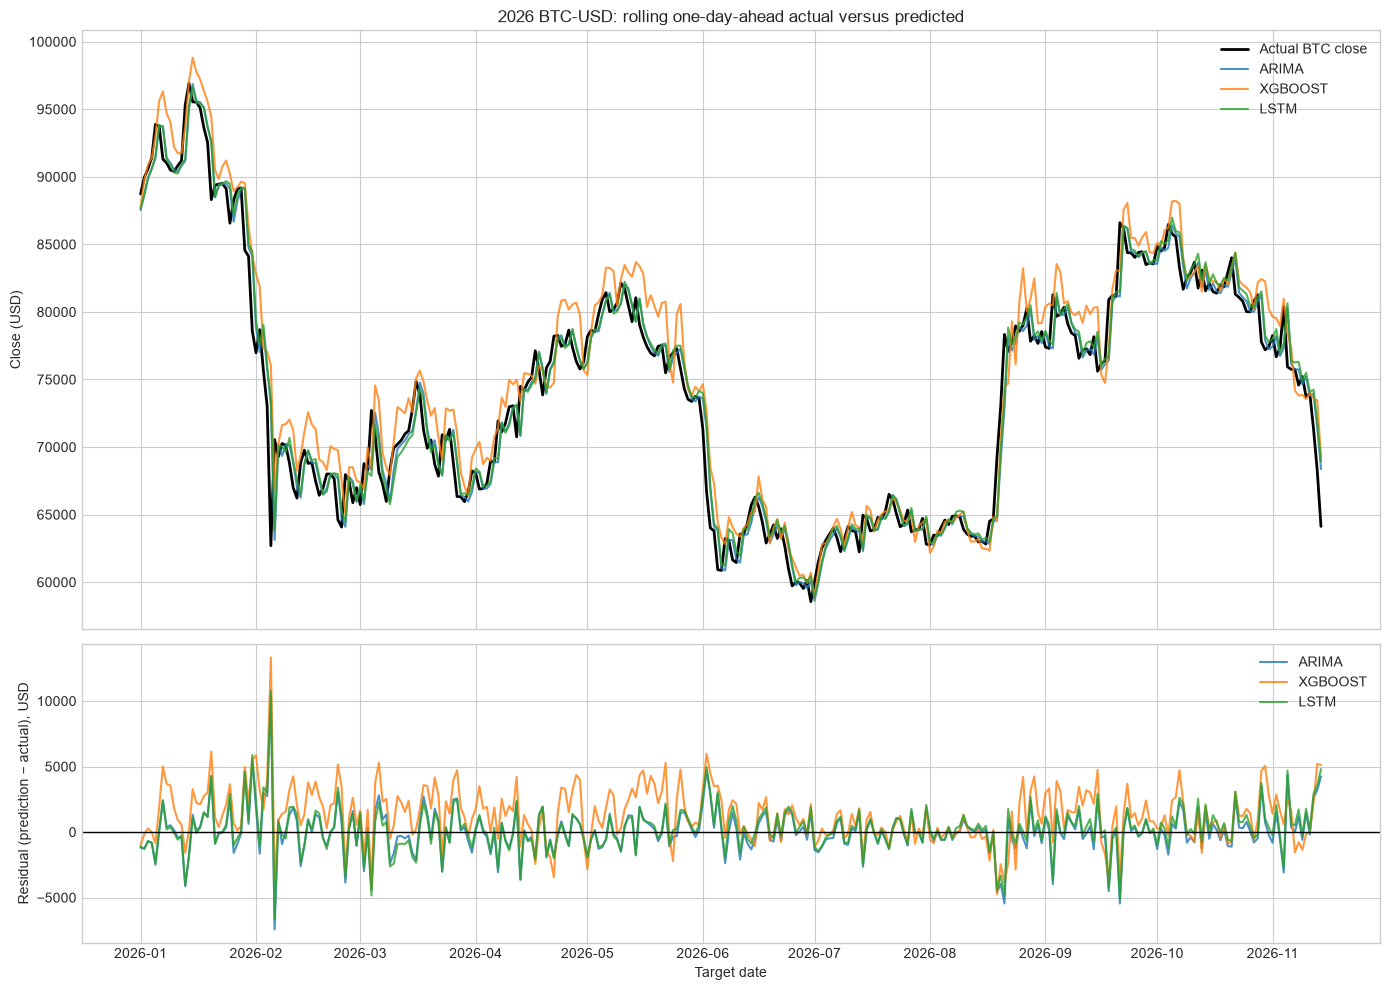

In [7]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from btc_forecasting.evaluation import compare_predictions

run_root = PROJECT_ROOT / "artifacts" / "runs"
matching_runs = {"arima": [], "xgboost": [], "lstm": []}
for candidate in run_root.iterdir() if run_root.exists() else []:
    if not candidate.is_dir():
        continue
    try:
        meta = json.loads((candidate / "metadata.json").read_text(encoding="utf-8"))
        model_name = meta.get("notebook_model")
        if (meta.get("notebook_experiment") and model_name in matching_runs
                and meta.get("raw_data_sha256") == RAW_SHA256
                and meta.get("split_ranges_by_target_date", {}).get("final_evaluation_target_dates") == SPLIT_CONFIG["final_evaluation_target_dates"]):
            matching_runs[model_name].append((candidate, meta))
    except (OSError, json.JSONDecodeError):
        continue

missing_models = [name for name, choices in matching_runs.items() if not choices]
if missing_models:
    print("Run the remaining model notebook(s), then re-execute this comparison cell: "
          + ", ".join(missing_models))
else:
    selected_runs = {
        name: sorted(choices, key=lambda item: item[0].name)[-1]
        for name, choices in matching_runs.items()
    }
    prediction_tables = {}
    for name, (folder, meta) in selected_runs.items():
        table = pd.read_csv(folder / "predictions.csv")
        table["Target_Date"] = pd.to_datetime(table["Target_Date"])
        table = table.set_index("Target_Date").sort_index()
        prediction_tables[name] = table
    common_dates = prediction_tables["arima"].index
    for table in prediction_tables.values():
        if not table.index.equals(common_dates):
            raise ValueError("The model runs do not cover exactly the same 2026 target dates.")
        if not np.allclose(table["actual_next_close_usd"], prediction_tables["arima"]["actual_next_close_usd"]):
            raise ValueError("The saved model runs disagree on actual close values.")
    actual = prediction_tables["arima"]["actual_next_close_usd"]
    previous = prediction_tables["arima"]["previous_close_usd"]
    forecasts = {
        name: table["prediction_usd"].rename(name)
        for name, table in prediction_tables.items()
    }
    comparison = compare_predictions(actual, previous, forecasts)
    display(comparison.round(4))
    comparison.to_csv(RUN_DIR / "three_model_comparison_2026.csv", index_label="model")

    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(actual.index, actual, label="Actual BTC close", color="black", linewidth=2)
    for name, forecast in forecasts.items():
        axes[0].plot(forecast.index, forecast, label=name.upper(), alpha=0.8)
        axes[1].plot(forecast.index, forecast - actual, label=name.upper(), alpha=0.8)
    axes[0].set_title("2026 BTC-USD: rolling one-day-ahead actual versus predicted")
    axes[0].set_ylabel("Close (USD)")
    axes[0].legend()
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_ylabel("Residual (prediction − actual), USD")
    axes[1].set_xlabel("Target date")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / "three_model_comparison_2026.png", dpi=160)
    display(fig)
    plt.close(fig)